# AgroSmart Puno · MIJAEL · DimensiónU1 — Temperatura exterior (Azángaro) · Arquitectura y ETL batch (S1 → S5)
**Estudiante:** Mijael Yurins Coaquira Justo · **Equipo Proyecto Sello:** Jose Armando Mamani Poccohuanca y Mijael Yurins Coaquira Justo

**Pregunta central del proyecto:** ¿cómo anticipar a corto plazo las condiciones meteorológicas de riesgo agrícola del altiplano de Puno (estrés hídrico del suelo y heladas) a partir de datos de Open-Meteo?
**Dimensión de Mijael:** *«¿Qué temperatura exterior se espera en la zona de referencia de Azángaro una hora después, a partir de los datos meteorológicos de Open-Meteo?»*
**DimensiónU1 (indicador batch, sin tiempo real):** perfil térmico histórico (mín./máx./media diaria, horas de helada) **y** la temperatura esperada a +1 h según un modelo de regresión entrenado una sola vez sobre el histórico («foto fija»).

| Sesión | Tema | Sección |
|---|---|---|
| S1 | Arquitectura Lambda/Kappa, batch vs. streaming | 1 |
| S2 | Fundamentos PySpark, lazy evaluation, agrupaciones, ventanas, RDD | 2 |
| S3 | Calidad de datos (−999, nulos, duplicados, **imputación con fuente de respaldo**) y Parquet particionado | 3 |
| S4 | ML distribuido con MLlib (regresión) con división **cronológica** | 4 |
| S5 | Evaluación de la Unidad I | 5 |

**Datos:** `data/AgroSmart_Temperatura_U1.xlsx` — **SIMULADOS** (120 días horarios, calibrados al clima del altiplano) con fallas inyectadas a propósito. No son mediciones. La Unidad 2 sí usa la API real de Open-Meteo.

> **Cómo ejecutar:** Jupyter `http://localhost:4489/lab` → abre este archivo desde `U1_Batch_Temperatura/` y ejecuta **de arriba hacia abajo**.

---
# SECCIÓN 1 · S1 — Arquitectura Big Data: Lambda y Kappa
## 1.1 Verificar el entorno (Docker + Jupyter + Spark)

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, math, time, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import StructType, StructField, StringType, DoubleType

RAIZ = Path('/home/jovyan/work/U1_Batch_Temperatura')
DATOS = RAIZ / 'data'; ARTIFACTS = RAIZ / 'artifacts'
for p in (DATOS, ARTIFACTS): p.mkdir(parents=True, exist_ok=True)

spark = (SparkSession.builder.appName('AgroSmart-U1-Temperatura').master('local[*]')
    .config('spark.ui.port', '4040').config('spark.sql.shuffle.partitions', '8')
    .config('spark.driver.memory', '2g').config('spark.sql.session.timeZone', 'UTC').getOrCreate())
spark.sparkContext.setLogLevel('WARN')
print('Spark', spark.version, '| Spark UI: http://localhost:4041')
print('Ejecución:', datetime.now(timezone.utc).isoformat())
print('Archivos:', sorted(p.name for p in DATOS.iterdir()))

Spark 3.5.0 | Spark UI: http://localhost:4041
Ejecución: 2026-11-20T05:48:46.517688+00:00
Archivos: ['AgroSmart_Temperatura_U1.xlsx', 'temperatura_2m.csv', 'temperatura_respaldo.csv']


## 1.2 Las 5V aplicadas a la temperatura de Azángaro
| V | En la dimensión de Mijael |
|---|---|
| **Volumen** | 1 lectura/hora; pequeño hoy, el *diseño* escala a más estaciones. |
| **Variedad** | Excel, CSV, JSON de la API, eventos Kafka, Parquet. |
| **Velocidad** | Dato horario de la API; el streaming lo procesa al llegar (Unidad 2). |
| **Veracidad** | Valores *modelados*; códigos de error (−999), nulos y duplicados; sensor de respaldo con sesgo. |
| **Valor** | Anticipar la temperatura a +1 h y vigilar el riesgo de **helada** (≤ 0 °C), fenómeno crítico en el altiplano. |

## 1.3 Batch vs. streaming (clasificación del caso)

In [2]:
display(pd.DataFrame([
 ['Perfil térmico histórico (mín/máx/media, horas de helada)', 'BATCH', 'Acumulado histórico procesado en bloque (U1).'],
 ['Limpiar, imputar con el respaldo y guardar Parquet', 'BATCH', 'ETL sobre archivos reutilizable por BI/ML.'],
 ['Entrenar el modelo de temperatura +1 h', 'BATCH', 'Se entrena una vez sobre el histórico.'],
 ['Recibir cada lectura horaria de la API', 'STREAMING', 'Evento nuevo cada hora (Kafka).'],
 ['Predecir +1 h y alertar helada al llegar cada lectura', 'STREAMING', 'Inferencia en vivo con el modelo del batch.'],
 ['Mostrar observada vs. predicha en Grafana', 'SERVING', 'Capa de consulta común del equipo.'],
], columns=['Tarea', 'Tipo', 'Justificación']))

,Tarea,Tipo,Justificación
0,"Perfil térmico histórico (mín/máx/media, horas...",BATCH,Acumulado histórico procesado en bloque (U1).
1,"Limpiar, imputar con el respaldo y guardar Par...",BATCH,ETL sobre archivos reutilizable por BI/ML.
2,Entrenar el modelo de temperatura +1 h,BATCH,Se entrena una vez sobre el histórico.
3,Recibir cada lectura horaria de la API,STREAMING,Evento nuevo cada hora (Kafka).
4,Predecir +1 h y alertar helada al llegar cada ...,STREAMING,Inferencia en vivo con el modelo del batch.
5,Mostrar observada vs. predicha en Grafana,SERVING,Capa de consulta común del equipo.


## 1.4 Decisión: arquitectura **LAMBDA**
Hay histórico (entrenar y describir) **y** tiempo real (inferir y alertar) → Lambda. Solo el **modelo entrenado** cruza del batch al speed layer; el riesgo es el *drift* si ambas capas calculan distinto, por eso la U2 usa las **mismas variables** que el modelo desplegable de esta sección (ablación en 4.4).
```
Excel/CSV ─► BATCH (PySpark + Parquet + MLlib) ─► modelo ─┐
API Open-Meteo ─► Kafka ─► SPEED (Structured Streaming) ──┴─► PostgreSQL ─► Grafana (tablero común del equipo)
```
## 1.5 Ficha de propuesta arquitectónica

In [3]:
ficha = pd.DataFrame({'Campo': ['Caso analizado','Tipo de procesamiento','Arquitectura','Tecnologías','Supuestos','Riesgos y límites'],
 'Dimensión de Mijael (temperatura)': [
  'Predicción de la temperatura exterior (°C, 2 m) a +1 h en la zona de referencia de Azángaro, con alerta didáctica de helada.',
  'AMBOS: batch (histórico, modelo) + streaming (inferencia por evento).',
  'LAMBDA (batch + speed + serving).',
  'Kafka · PySpark/MLlib · Structured Streaming · Parquet + PostgreSQL · Grafana · Prometheus.',
  'La hora del día y las últimas lecturas explican gran parte de la temperatura a +1 h; Open-Meteo representa la zona.',
  'Datos modelados (no termómetro); histórico U1 simulado; un solo nodo; umbral de helada (0 °C) didáctico; no es pronóstico oficial.']})
with pd.option_context('display.max_colwidth', None): display(ficha)

,Campo,Dimensión de Mijael (temperatura)
0,Caso analizado,"Predicción de la temperatura exterior (°C, 2 m) a +1 h en la zona de referencia de Azángaro, con alerta didáctica de helada."
1,Tipo de procesamiento,"AMBOS: batch (histórico, modelo) + streaming (inferencia por evento)."
2,Arquitectura,LAMBDA (batch + speed + serving).
3,Tecnologías,Kafka · PySpark/MLlib · Structured Streaming · Parquet + PostgreSQL · Grafana · Prometheus.
4,Supuestos,La hora del día y las últimas lecturas explican gran parte de la temperatura a +1 h; Open-Meteo representa la zona.
5,Riesgos y límites,Datos modelados (no termómetro); histórico U1 simulado; un solo nodo; umbral de helada (0 °C) didáctico; no es pronóstico oficial.


## 1.6 Calibración contra la API real (opcional, necesita internet)
Contrasta el clima simulado con los últimos 60 días reales de Open-Meteo para Azángaro. Si no hay internet, se omite sin error.

In [4]:
sys.path.insert(0, '/home/jovyan/agrosmart-repo/uso-agrosmart/producer')
try:
    from open_meteo_temperatura import consultar_api
    reg, meta = consultar_api(-14.91, -70.19, dias=60, ubicacion='Azángaro')
    real = pd.DataFrame(reg)
    sim_csv = pd.read_csv(DATOS/'temperatura_2m.csv'); sim_csv = sim_csv[sim_csv.temperatura_c > -900]
    comp = pd.DataFrame({'API real (60 d)': real.temperatura_c.describe(), 'Simulado U1 (120 d)': sim_csv.temperatura_c.describe()}).round(2)
    display(comp); print('Horas bajo 0 °C → API:', round((real.temperatura_c < 0).mean()*100, 1), '% | simulado:', round((sim_csv.temperatura_c < 0).mean()*100, 1), '%')
except Exception as e:
    print('Se omite la calibración (sin internet o API no disponible):', e)

,API real (60 d),Simulado U1 (120 d)
count,1464.00,2835.00
mean,10.10,8.59
std,5.68,5.58
min,-2.90,-5.40
25%,5.80,4.30
50%,9.50,8.60
75%,15.00,12.90
max,21.80,23.40


Horas bajo 0 °C → API: 2.3 % | simulado: 5.8 %


### 1.7 Reflexión S1
Para sensores IoT con histórico y necesidad de reaccionar en vivo elegí **Lambda**: el modelo se entrena sobre meses de datos (batch) y se aplica a cada lectura (speed). **Kappa** bastaría si todo se resolviera reproduciendo el tópico de Kafka. El costo de Lambda es mantener dos capas y cuidar que no diverjan.

---
# SECCIÓN 2 · S2 — Fundamentos PySpark
## 2.1 El Excel de negocio y los CSV
Verificamos que el Excel y los CSV contengan lo mismo (Spark lee CSV/Parquet).

In [5]:
try:
    hojas = pd.read_excel(DATOS/'AgroSmart_Temperatura_U1.xlsx', sheet_name=None)
    print({k: v.shape for k, v in hojas.items()}); display(hojas['diccionario'])
    assert len(hojas['temperatura_2m']) == len(pd.read_csv(DATOS/'temperatura_2m.csv'))
    print('Excel y CSV coinciden.')
except ImportError:
    print('openpyxl no instalado: se usan solo los CSV (reconstruye con --build).')

{'temperatura_2m': (2880, 2), 'temperatura_respaldo': (2905, 2), 'diccionario': (4, 4)}


,hoja,columna,unidad,descripcion
0,temperatura_2m,fecha_hora,"UTC, cada hora",Clave de integración
1,temperatura_2m,temperatura_c,°C,OBJETIVO. -999 = error de sensor; vacío = nulo...
2,temperatura_respaldo,fecha_hora,"UTC, cada hora",Clave; puede venir DUPLICADA
3,temperatura_respaldo,temperatura_respaldo_c,°C,Sensor de respaldo SIMULADO (sesgo +0.4 °C); s...


Excel y CSV coinciden.


## 2.2 Carga con esquema explícito

In [6]:
sch_a = StructType([StructField('fecha_hora', StringType(), True), StructField('temperatura_c', DoubleType(), True)])
sch_b = StructType([StructField('fecha_hora', StringType(), True), StructField('temperatura_respaldo_c', DoubleType(), True)])
df_a = spark.read.csv(str(DATOS/'temperatura_2m.csv'), header=True, schema=sch_a)
df_b = spark.read.csv(str(DATOS/'temperatura_respaldo.csv'), header=True, schema=sch_b)
for n, d in [('temperatura_2m (principal)', df_a), ('temperatura_respaldo', df_b)]:
    print(f'== {n}: {d.count():,} filas'); d.printSchema()
df_a.show(5, truncate=False); df_a.describe('temperatura_c').show()

== temperatura_2m (principal): 2,880 filas
root
 |-- fecha_hora: string (nullable = true)
 |-- temperatura_c: double (nullable = true)

== temperatura_respaldo: 2,905 filas
root
 |-- fecha_hora: string (nullable = true)
 |-- temperatura_respaldo_c: double (nullable = true)

+-------------------+-------------+
|fecha_hora         |temperatura_c|
+-------------------+-------------+
|2026-07-14 00:00:00|8.5          |
|2026-07-14 01:00:00|7.9          |
|2026-07-14 02:00:00|6.7          |
|2026-07-14 03:00:00|5.7          |
|2026-07-14 04:00:00|4.6          |
+-------------------+-------------+
only showing top 5 rows

+-------+-------------------+
|summary|      temperatura_c|
+-------+-------------------+
|  count|               2865|
|   mean|-1.9642931937172783|
| stddev| 102.73192979040888|
|    min|             -999.0|
|    max|               23.4|
+-------+-------------------+



## 2.3 Transformaciones vs. acciones (lazy evaluation) y `explain(True)`

In [7]:
t0 = time.perf_counter()
plan = (df_a.select('fecha_hora', 'temperatura_c').filter((F.col('temperatura_c') > -900) & (F.col('temperatura_c') < 0))
        .withColumn('grados_bajo_cero', -F.col('temperatura_c')))
t_plan = time.perf_counter() - t0
t0 = time.perf_counter(); n = plan.count(); t_acc = time.perf_counter() - t0
print(f'Plan (transformaciones): {t_plan*1000:.1f} ms → no leyó datos')
print(f'Acción count():          {t_acc*1000:.1f} ms → {n} lecturas bajo 0 °C')
plan.explain(True)

Plan (transformaciones): 77.1 ms → no leyó datos
Acción count():          386.6 ms → 164 lecturas bajo 0 °C
== Parsed Logical Plan ==
'Project [fecha_hora#0, temperatura_c#1, -'temperatura_c AS grados_bajo_cero#129]
+- Filter ((temperatura_c#1 > cast(-900 as double)) AND (temperatura_c#1 < cast(0 as double)))
   +- Project [fecha_hora#0, temperatura_c#1]
      +- Relation [fecha_hora#0,temperatura_c#1] csv

== Analyzed Logical Plan ==
fecha_hora: string, temperatura_c: double, grados_bajo_cero: double
Project [fecha_hora#0, temperatura_c#1, -temperatura_c#1 AS grados_bajo_cero#129]
+- Filter ((temperatura_c#1 > cast(-900 as double)) AND (temperatura_c#1 < cast(0 as double)))
   +- Project [fecha_hora#0, temperatura_c#1]
      +- Relation [fecha_hora#0,temperatura_c#1] csv

== Optimized Logical Plan ==
Project [fecha_hora#0, temperatura_c#1, -temperatura_c#1 AS grados_bajo_cero#129]
+- Filter (isnotnull(temperatura_c#1) AND ((temperatura_c#1 > -900.0) AND (temperatura_c#1 < 0.0)))
   +-

Lectura del plan (de abajo hacia arriba): *Parsed* = tu código; *Analyzed* = tipos resueltos; *Optimized* = Catalyst reordena y agrega `isnotnull`; *Physical* = `FileScan csv` con `PushedFilters` y solo las columnas necesarias (*predicate pushdown* y *column pruning*).

## 2.4 `withColumn`: cast, to_timestamp, when/otherwise, lit, current_date

In [8]:
df_s = (df_a
    .withColumn('ts', F.to_timestamp('fecha_hora', 'yyyy-MM-dd HH:mm:ss'))
    .withColumn('hora_utc', F.hour('ts'))
    .withColumn('categoria_termica',
        F.when(F.col('temperatura_c') == -999, 'ERROR_SENSOR').when(F.col('temperatura_c').isNull(), 'SIN_DATO')
         .when(F.col('temperatura_c') < 0, 'HELADA').when(F.col('temperatura_c') <= 5, 'FRIO')
         .when(F.col('temperatura_c') <= 15, 'TEMPLADO').otherwise('CALIDO'))
    .withColumn('fuente', F.lit('SIMULADO calibrado al altiplano')).withColumn('fecha_procesado', F.current_date()))
df_s.select('fecha_hora', 'temperatura_c', 'categoria_termica', 'hora_utc', 'fuente').show(8, truncate=False)

+-------------------+-------------+-----------------+--------+-------------------------------+
|fecha_hora         |temperatura_c|categoria_termica|hora_utc|fuente                         |
+-------------------+-------------+-----------------+--------+-------------------------------+
|2026-07-14 00:00:00|8.5          |TEMPLADO         |0       |SIMULADO calibrado al altiplano|
|2026-07-14 01:00:00|7.9          |TEMPLADO         |1       |SIMULADO calibrado al altiplano|
|2026-07-14 02:00:00|6.7          |TEMPLADO         |2       |SIMULADO calibrado al altiplano|
|2026-07-14 03:00:00|5.7          |TEMPLADO         |3       |SIMULADO calibrado al altiplano|
|2026-07-14 04:00:00|4.6          |FRIO             |4       |SIMULADO calibrado al altiplano|
|2026-07-14 05:00:00|4.5          |FRIO             |5       |SIMULADO calibrado al altiplano|
|2026-07-14 06:00:00|3.6          |FRIO             |6       |SIMULADO calibrado al altiplano|
|2026-07-14 07:00:00|1.2          |FRIO           

## 2.5 Agrupaciones: categorías, resumen diario (mín/máx/media/horas de helada) y perfil por hora

+-----------------+--------+-------+
|categoria_termica|lecturas|media_c|
+-----------------+--------+-------+
|         TEMPLADO|    1629|  10.01|
|             FRIO|     668|   2.69|
|           CALIDO|     374|  17.37|
|           HELADA|     164|  -1.54|
+-----------------+--------+-------+



,dia,t_min,t_max,t_media,horas_helada,amplitud_c
112,2026-11-03,0.0,14.4,7.98,0,14.4
113,2026-11-04,3.4,17.4,9.65,0,14.0
114,2026-11-05,1.1,16.6,9.55,0,15.5
115,2026-11-06,5.1,20.4,12.17,0,15.3
116,2026-11-07,7.7,23.1,14.89,0,15.4
117,2026-11-08,5.9,19.9,13.35,0,14.0
118,2026-11-09,7.8,20.4,13.50,0,12.6
119,2026-11-10,8.4,23.4,15.20,0,15.0


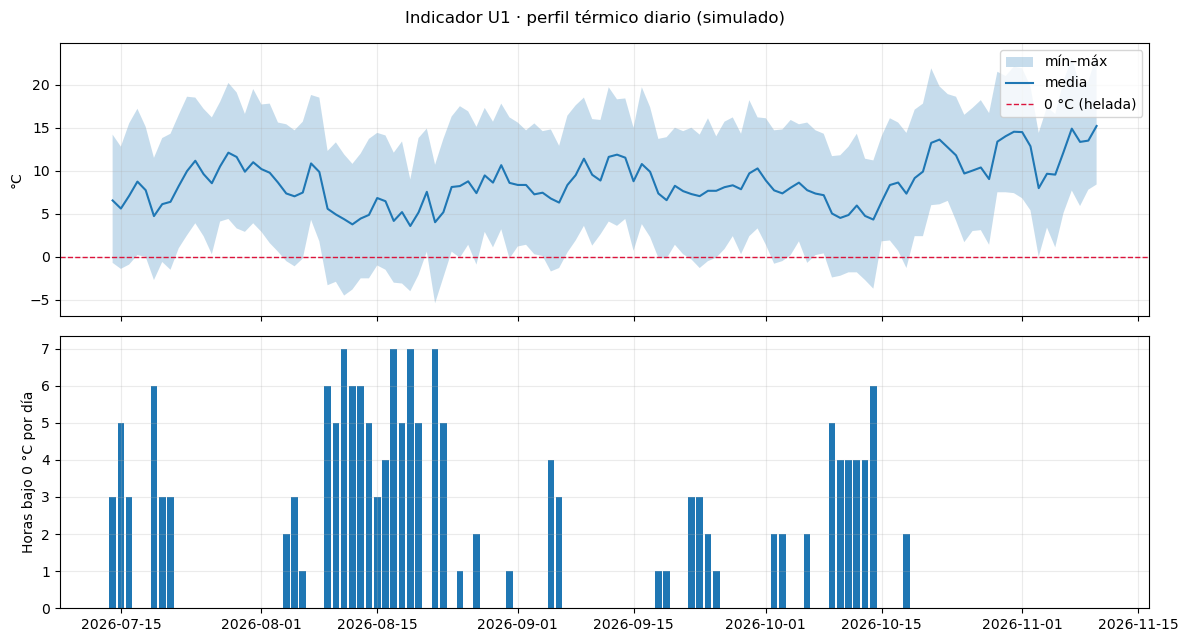

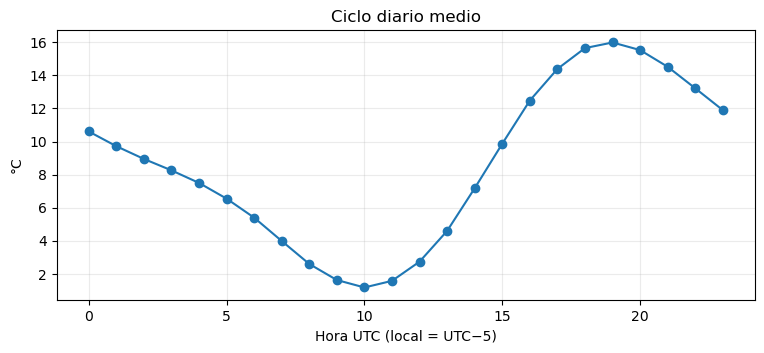

In [9]:
validos = df_s.filter(~F.col('categoria_termica').isin('ERROR_SENSOR', 'SIN_DATO'))
validos.groupBy('categoria_termica').agg(F.count('*').alias('lecturas'), F.round(F.avg('temperatura_c'), 2).alias('media_c')).orderBy(F.desc('lecturas')).show()

diario = (validos.groupBy(F.to_date('ts').alias('dia'))
    .agg(F.round(F.min('temperatura_c'), 1).alias('t_min'), F.round(F.max('temperatura_c'), 1).alias('t_max'),
         F.round(F.avg('temperatura_c'), 2).alias('t_media'), F.sum(F.when(F.col('temperatura_c') < 0, 1).otherwise(0)).alias('horas_helada'))
    .withColumn('amplitud_c', F.round(F.col('t_max') - F.col('t_min'), 1)).orderBy('dia'))
dp = diario.toPandas(); display(dp.tail(8))
dp.to_csv(ARTIFACTS/'resumen_diario_temperatura.csv', index=False)
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].fill_between(pd.to_datetime(dp.dia), dp.t_min, dp.t_max, alpha=.25, label='mín–máx'); ax[0].plot(pd.to_datetime(dp.dia), dp.t_media, label='media')
ax[0].axhline(0, color='crimson', ls='--', lw=1, label='0 °C (helada)'); ax[0].set_ylabel('°C'); ax[0].legend(); ax[0].grid(alpha=.25)
ax[1].bar(pd.to_datetime(dp.dia), dp.horas_helada); ax[1].set_ylabel('Horas bajo 0 °C por día'); ax[1].grid(alpha=.25)
fig.suptitle('Indicador U1 · perfil térmico diario (simulado)'); plt.tight_layout(); fig.savefig(ARTIFACTS/'u1_perfil_diario.png', dpi=150); plt.show()

ph = validos.groupBy('hora_utc').agg(F.round(F.avg('temperatura_c'), 2).alias('media')).orderBy('hora_utc').toPandas()
plt.figure(figsize=(9, 3.5)); plt.plot(ph.hora_utc, ph.media, marker='o'); plt.xlabel('Hora UTC (local = UTC−5)'); plt.ylabel('°C'); plt.title('Ciclo diario medio'); plt.grid(alpha=.25); plt.show()

## 2.6 Función ventana (`Window`): media móvil de 3 h y cambio respecto a la hora anterior (sin perder filas)

In [10]:
v = Window.orderBy('ts')
vent = (validos.withColumn('media_movil_3h', F.round(F.avg('temperatura_c').over(v.rowsBetween(-2, 0)), 2))
               .withColumn('cambio_vs_hora_anterior', F.round(F.col('temperatura_c') - F.lag('temperatura_c', 1).over(v), 2)))
vent.select('fecha_hora', 'temperatura_c', 'media_movil_3h', 'cambio_vs_hora_anterior').orderBy('ts').show(8, truncate=False)

+-------------------+-------------+--------------+-----------------------+
|fecha_hora         |temperatura_c|media_movil_3h|cambio_vs_hora_anterior|
+-------------------+-------------+--------------+-----------------------+
|2026-07-14 00:00:00|8.5          |8.5           |NULL                   |
|2026-07-14 01:00:00|7.9          |8.2           |-0.6                   |
|2026-07-14 02:00:00|6.7          |7.7           |-1.2                   |
|2026-07-14 03:00:00|5.7          |6.77          |-1.0                   |
|2026-07-14 04:00:00|4.6          |5.67          |-1.1                   |
|2026-07-14 05:00:00|4.5          |4.93          |-0.1                   |
|2026-07-14 06:00:00|3.6          |4.23          |-0.9                   |
|2026-07-14 07:00:00|1.2          |3.1           |-2.4                   |
+-------------------+-------------+--------------+-----------------------+
only showing top 8 rows



## 2.7 RDD (map / reduceByKey) y `cache()`

In [11]:
from operator import add
conteo = df_s.select('categoria_termica').rdd.map(lambda r: (r.categoria_termica, 1)).reduceByKey(add)
print(sorted(conteo.collect(), key=lambda x: -x[1]))
print(sorted([(r.categoria_termica, r['count']) for r in df_s.groupBy('categoria_termica').count().collect()], key=lambda x: -x[1]))
c_df = validos.cache(); t0 = time.perf_counter(); c_df.count(); t1 = time.perf_counter() - t0
t0 = time.perf_counter(); c_df.count(); t2 = time.perf_counter() - t0
print(f'1.ª acción {t1*1000:.0f} ms · 2.ª (caché) {t2*1000:.0f} ms'); c_df.unpersist();

[('TEMPLADO', 1629), ('FRIO', 668), ('CALIDO', 374), ('HELADA', 164), ('ERROR_SENSOR', 30), ('SIN_DATO', 15)]
[('TEMPLADO', 1629), ('FRIO', 668), ('CALIDO', 374), ('HELADA', 164), ('ERROR_SENSOR', 30), ('SIN_DATO', 15)]
1.ª acción 627 ms · 2.ª (caché) 187 ms


### Hallazgos S2
Transformación ≠ acción (2.3); `explain` muestra pushdown (2.3); ventana conserva filas, `groupBy` las colapsa (2.5–2.6); el RDD no usa Catalyst (2.7). **Advertencia:** son temperaturas **simuladas** del aire a 2 m; no hay termómetro físico.

---
# SECCIÓN 3 · S3 — Calidad de datos y particionamiento
Bronze = CSV/Excel · Silver = limpio e integrado · Gold = Parquet particionado por `anio_mes`.
## 3.1 Validación de esquema, nulos y códigos de error

In [12]:
req = {'a': {'fecha_hora', 'temperatura_c'}, 'b': {'fecha_hora', 'temperatura_respaldo_c'}}
for k, d in (('a', df_a), ('b', df_b)):
    falta = req[k] - set(d.columns)
    if falta: raise ValueError(f'faltan columnas {falta}')
print('Esquema validado.')
tot_a = df_a.count(); tot_b = df_b.count()
def nulos(d): return d.select([F.count(F.when(F.col(c).isNull(), c)).alias(c) for c in d.columns]).collect()[0].asDict()
n_a, n_b = nulos(df_a), nulos(df_b)
n_err = df_a.filter(F.col('temperatura_c') == -999).count()
print('Nulos principal:', n_a, '| Nulos respaldo:', n_b); print(f'Códigos -999: {n_err} ({n_err/tot_a*100:.2f} %)')
pa = pd.read_csv(DATOS/'temperatura_2m.csv'); pb = pd.read_csv(DATOS/'temperatura_respaldo.csv')
assert n_err == int((pa.temperatura_c == -999).sum()) and n_a['temperatura_c'] == int(pa.temperatura_c.isna().sum())
print('OK: Spark = pandas.')

Esquema validado.
Nulos principal: {'fecha_hora': 0, 'temperatura_c': 15} | Nulos respaldo: {'fecha_hora': 0, 'temperatura_respaldo_c': 23}
Códigos -999: 30 (1.04 %)
OK: Spark = pandas.


## 3.2 Duplicados en la fuente de respaldo
Un `join` con clave duplicada multiplica filas sin error. Se diagnostica y se trata con `Window + row_number`, conservando la fila con **menos nulos**.

In [13]:
dups = df_b.groupBy('fecha_hora').count().filter('count > 1'); print('Marcas duplicadas en respaldo:', dups.count()); dups.show(5, truncate=False)
b_n = df_b.withColumn('n_nulos', F.when(F.col('temperatura_respaldo_c').isNull(), 1).otherwise(0))
w = Window.partitionBy('fecha_hora').orderBy(F.col('n_nulos').asc(), F.col('temperatura_respaldo_c').desc_nulls_last())
b_u = b_n.withColumn('rn', F.row_number().over(w)).filter('rn = 1').drop('rn', 'n_nulos')
print(f'Respaldo: {tot_b} → {b_u.count()} filas únicas')
assert b_u.count() == pb.fecha_hora.nunique() == b_u.dropDuplicates(['fecha_hora']).count()

Marcas duplicadas en respaldo: 25
+-------------------+-----+
|fecha_hora         |count|
+-------------------+-----+
|2026-07-29 06:00:00|2    |
|2026-07-29 17:00:00|2    |
|2026-08-11 12:00:00|2    |
|2026-08-18 10:00:00|2    |
|2026-07-23 23:00:00|2    |
+-------------------+-----+
only showing top 5 rows

Respaldo: 2905 → 2880 filas únicas


## 3.3 Silver: **imputar con la fuente de respaldo** (en vez de descartar)
Reglas: (1) `−999` y nulos de la fuente principal se **tratan como faltantes**; (2) si el respaldo tiene dato, se usa y se marca `imputada=true` (el respaldo tiene un sesgo de ≈+0.4 °C: se documenta, no se oculta); (3) si ninguna fuente tiene dato, se **descarta** la fila; (4) control de dominio −60…60 °C.

In [14]:
a2 = (df_a.withColumn('ts', F.to_timestamp('fecha_hora', 'yyyy-MM-dd HH:mm:ss'))
      .withColumn('temp_principal', F.when(~((F.col('temperatura_c') == -999) | F.col('temperatura_c').isNull()), F.col('temperatura_c')))
      .select('fecha_hora', 'ts', 'temp_principal'))
silver = (a2.join(b_u, 'fecha_hora', 'left')
    .withColumn('temperatura_c', F.coalesce('temp_principal', 'temperatura_respaldo_c'))
    .withColumn('imputada', F.col('temp_principal').isNull() & F.col('temperatura_respaldo_c').isNotNull())
    .filter(F.col('temperatura_c').isNotNull() & F.col('temperatura_c').between(-60, 60))
    .select('ts', 'temperatura_c', 'imputada').orderBy('ts')).cache()
n_silver = silver.count(); n_imp = silver.filter('imputada').count()
print(f'Silver: {n_silver:,} filas (Bronze {tot_a:,}) · imputadas con respaldo: {n_imp} · descartadas: {tot_a - n_silver}')
assert n_silver == silver.dropDuplicates(['ts']).count(), 'ts repetido'
# Verificación independiente con pandas
pb2 = pb.assign(n=pb.temperatura_respaldo_c.isna().astype(int)).sort_values(['fecha_hora', 'n', 'temperatura_respaldo_c'], ascending=[True, True, False]).drop_duplicates('fecha_hora')
m = pa.merge(pb2[['fecha_hora', 'temperatura_respaldo_c']], on='fecha_hora', how='left')
malo = (m.temperatura_c == -999) | m.temperatura_c.isna()
final = m.temperatura_c.where(~malo, m.temperatura_respaldo_c)
assert int(final.notna().sum()) == n_silver and int((malo & m.temperatura_respaldo_c.notna()).sum()) == n_imp
print('OK: Spark = pandas (filas e imputaciones).'); silver.show(5, truncate=False)

Silver: 2,880 filas (Bronze 2,880) · imputadas con respaldo: 45 · descartadas: 0
OK: Spark = pandas (filas e imputaciones).
+-------------------+-------------+--------+
|ts                 |temperatura_c|imputada|
+-------------------+-------------+--------+
|2026-07-14 00:00:00|8.5          |false   |
|2026-07-14 01:00:00|7.9          |false   |
|2026-07-14 02:00:00|6.7          |false   |
|2026-07-14 03:00:00|5.7          |false   |
|2026-07-14 04:00:00|4.6          |false   |
+-------------------+-------------+--------+
only showing top 5 rows



## 3.4 Filtrado y orden: `between` es inclusivo

In [15]:
print('between(0,5):', silver.filter(F.col('temperatura_c').between(0, 5)).count(), '| estricto (0,5):', silver.filter((F.col('temperatura_c') > 0) & (F.col('temperatura_c') < 5)).count())
silver.orderBy(F.col('temperatura_c').asc(), F.col('ts').asc()).show(5, truncate=False)   # los 5 momentos más fríos

between(0,5): 675 | estricto (0,5): 653
+-------------------+-------------+--------+
|ts                 |temperatura_c|imputada|
+-------------------+-------------+--------+
|2026-08-22 10:00:00|-5.4         |false   |
|2026-08-22 11:00:00|-5.0         |false   |
|2026-08-11 10:00:00|-4.5         |false   |
|2026-08-19 11:00:00|-4.0         |false   |
|2026-08-22 09:00:00|-4.0         |false   |
+-------------------+-------------+--------+
only showing top 5 rows



## 3.5 Gold: Parquet particionado por mes y lectura de vuelta

In [16]:
gold_path = str(ARTIFACTS / 'temperatura_gold_particionado')
gold = silver.withColumn('anio_mes', F.date_format('ts', 'yyyy-MM'))
gold.repartition(2).write.format('parquet').mode('overwrite').partitionBy('anio_mes').save(gold_path)
print('Particiones:', sorted(p for p in os.listdir(gold_path) if p.startswith('anio_mes')))
leido = spark.read.parquet(gold_path); assert leido.count() == n_silver
leido.groupBy('anio_mes').count().orderBy('anio_mes').show()
leido.filter(F.col('anio_mes') == '2026-10').explain(True)   # busca PartitionFilters

Particiones: ['anio_mes=2026-07', 'anio_mes=2026-08', 'anio_mes=2026-09', 'anio_mes=2026-10', 'anio_mes=2026-11']
+--------+-----+
|anio_mes|count|
+--------+-----+
| 2026-07|  432|
| 2026-08|  744|
| 2026-09|  720|
| 2026-10|  744|
| 2026-11|  240|
+--------+-----+

== Parsed Logical Plan ==
'Filter ('anio_mes = 2026-10)
+- Relation [ts#1559,temperatura_c#1560,imputada#1561,anio_mes#1562] parquet

== Analyzed Logical Plan ==
ts: timestamp, temperatura_c: double, imputada: boolean, anio_mes: string
Filter (anio_mes#1562 = 2026-10)
+- Relation [ts#1559,temperatura_c#1560,imputada#1561,anio_mes#1562] parquet

== Optimized Logical Plan ==
Filter (isnotnull(anio_mes#1562) AND (anio_mes#1562 = 2026-10))
+- Relation [ts#1559,temperatura_c#1560,imputada#1561,anio_mes#1562] parquet

== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [ts#1559,temperatura_c#1560,imputada#1561,anio_mes#1562] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/home/j

`PartitionFilters` descarta **carpetas** enteras sin abrir archivos; `PushedFilters` filtra filas dentro de los archivos abiertos.

---
# SECCIÓN 4 · S4 — ML distribuido con MLlib (regresión, CRISP‑DM)
**Objetivo:** estimar la **temperatura a +1 h** a partir de la lectura actual, las dos anteriores y la hora del día. En una serie de tiempo **no se baraja**: la división es **cronológica** (80 % pasado → 20 % futuro).
## 4.1 Preparación de variables con funciones ventana (`lag`/`lead`)

In [17]:
w = Window.orderBy('ts')
base = (silver.select('ts', 'temperatura_c')
    .withColumn('t_lag1', F.lag('temperatura_c', 1).over(w)).withColumn('t_lag2', F.lag('temperatura_c', 2).over(w))
    .withColumn('ts_p1', F.lag('ts', 1).over(w)).withColumn('ts_p2', F.lag('ts', 2).over(w))
    .withColumn('label', F.lead('temperatura_c', 1).over(w)).withColumn('ts_n1', F.lead('ts', 1).over(w))
    .withColumn('delta1', F.col('temperatura_c') - F.col('t_lag1'))
    .withColumn('hora_seno', F.sin(F.hour('ts') * F.lit(2*math.pi/24))).withColumn('hora_coseno', F.cos(F.hour('ts') * F.lit(2*math.pi/24)))
    .withColumn('ts_unix', F.unix_timestamp('ts')))
u = F.unix_timestamp
continuo = ((u('ts') - u('ts_p1') == 3600) & (u('ts_p1') - u('ts_p2') == 3600) & (u('ts_n1') - u('ts') == 3600))   # sin huecos
ml = base.filter(continuo & F.col('label').isNotNull()).cache()
print('Filas utilizables:', ml.count())
corte = ml.approxQuantile('ts_unix', [0.8], 0.001)[0]
train, test = ml.filter(F.col('ts_unix') <= corte), ml.filter(F.col('ts_unix') > corte)
print(f'Entrenamiento (pasado): {train.count():,} · Prueba (futuro): {test.count():,} · corte UTC: {datetime.fromtimestamp(corte, timezone.utc)}')

Filas utilizables: 2877
Entrenamiento (pasado): 2,299 · Prueba (futuro): 578 · corte UTC: 2026-10-17 20:00:00+00:00


## 4.2 Modelos y métricas (RMSE, MAE, R² en °C) frente a **persistencia** (predecir «igual que ahora»)

In [18]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
COMPLETO = ['temperatura_c', 't_lag1', 't_lag2', 'delta1', 'hora_seno', 'hora_coseno']
DESPLEGABLE = ['temperatura_c', 'hora_seno', 'hora_coseno']      # lo único que tiene el streaming por evento (U2)
def vec(df, cols): return VectorAssembler(inputCols=cols, outputCol='features', handleInvalid='skip').transform(df).select('features', 'label', 'temperatura_c')
def evaluar(pred, nombre, conjunto):
    ev = lambda m: RegressionEvaluator(labelCol='label', predictionCol='prediction', metricName=m).evaluate(pred)
    return {'Modelo': nombre, 'Variables': conjunto, 'RMSE_C': ev('rmse'), 'MAE_C': ev('mae'), 'R2': ev('r2')}
res, modelos = [], {}
res.append(evaluar(vec(test, COMPLETO).withColumn('prediction', F.col('temperatura_c')), 'Persistencia (baseline)', '—'))
for conjunto, cols in (('completo (con lags)', COMPLETO), ('desplegable en U2', DESPLEGABLE)):
    tr, te = vec(train, cols).cache(), vec(test, cols)
    for nombre, est in [('Lineal', LinearRegression(featuresCol='features', labelCol='label')),
                        ('Ridge', LinearRegression(featuresCol='features', labelCol='label', regParam=0.1, elasticNetParam=0.0)),
                        ('Random Forest', RandomForestRegressor(featuresCol='features', labelCol='label', numTrees=50, maxDepth=8, seed=42)),
                        ('GBT', GBTRegressor(featuresCol='features', labelCol='label', maxIter=30, maxDepth=5, seed=42))]:
        m = est.fit(tr); modelos[(nombre, conjunto)] = (m, cols); res.append(evaluar(m.transform(te), nombre, conjunto))
comp = pd.DataFrame(res).round(4); display(comp.sort_values('RMSE_C'))
comp.to_csv(ARTIFACTS/'u1_comparacion_modelos.csv', index=False)

,Modelo,Variables,RMSE_C,MAE_C,R2
1,Lineal,completo (con lags),0.9155,0.7028,0.9702
2,Ridge,completo (con lags),0.9673,0.7495,0.9668
5,Lineal,desplegable en U2,0.9728,0.7647,0.9664
6,Ridge,desplegable en U2,1.0730,0.8389,0.9591
8,GBT,desplegable en U2,1.3643,0.9502,0.9339
4,GBT,completo (con lags),1.3911,0.9651,0.9312
3,Random Forest,completo (con lags),1.3939,1.0236,0.9310
0,Persistencia (baseline),—,1.4965,1.2490,0.9204
7,Random Forest,desplegable en U2,2.0806,1.6467,0.8462


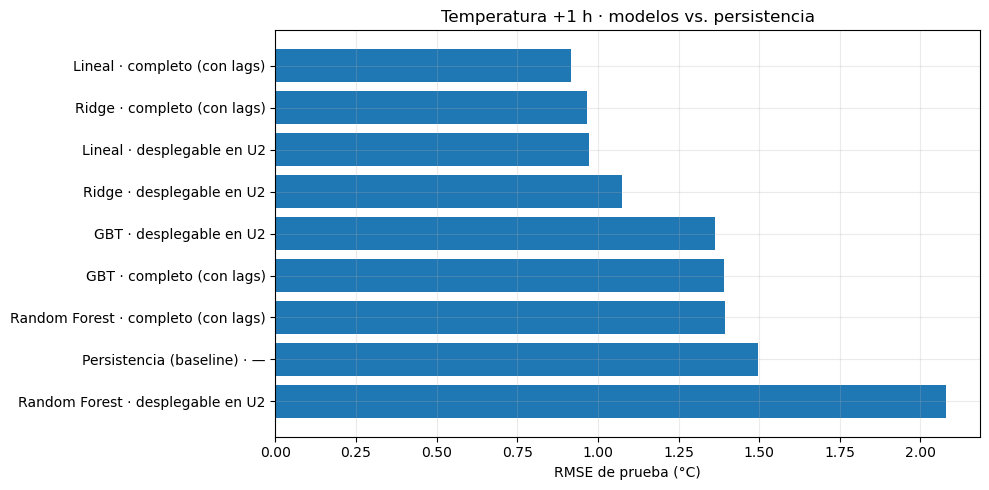

In [19]:
c2 = comp.sort_values('RMSE_C'); etq = c2.Modelo + ' · ' + c2.Variables
plt.figure(figsize=(10, 5)); plt.barh(etq[::-1], c2.RMSE_C[::-1]); plt.xlabel('RMSE de prueba (°C)'); plt.title('Temperatura +1 h · modelos vs. persistencia')
plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(ARTIFACTS/'u1_comparacion_modelos.png', dpi=150); plt.show()

## 4.3 Selección y **Indicador U1: temperatura esperada a +1 h** (foto fija)
El ganador se elige por la tabla (menor RMSE de prueba) y debe **superar la persistencia**; si no lo hace, **se reporta tal cual**. La predicción es una foto fija: se calcula al correr el pipeline y no se actualiza dato por dato (eso es la DimensiónU2).

In [20]:
base_rmse = float(comp[comp.Modelo == 'Persistencia (baseline)'].RMSE_C.iloc[0])
cand = comp[comp.Modelo != 'Persistencia (baseline)'].sort_values('RMSE_C'); mejor = cand.iloc[0]
print(f'Ganador: {mejor.Modelo} · {mejor.Variables} | RMSE={mejor.RMSE_C:.3f} °C MAE={mejor.MAE_C:.3f} R2={mejor.R2:.4f} | persistencia RMSE={base_rmse:.3f} °C')
print('¿Supera a la persistencia?', bool(mejor.RMSE_C < base_rmse), f'(mejora {(1-mejor.RMSE_C/base_rmse)*100:.1f} % del error)')
mod, cols = modelos[(mejor.Modelo, mejor.Variables)]
mod.write().overwrite().save(str(ARTIFACTS/'modelo_u1_temperatura_1h'))
ultima = base.orderBy(F.col('ts').desc()).limit(1)
fila = VectorAssembler(inputCols=cols, outputCol='features', handleInvalid='skip').transform(ultima)
p = mod.transform(fila).select('ts', 'temperatura_c', 'prediction').collect()[0]
print(f'INDICADOR U1 → a las {p.ts} UTC la temperatura fue {p.temperatura_c:.1f} °C; el modelo espera {p.prediction:.2f} °C una hora después (foto fija).')

Ganador: Lineal · completo (con lags) | RMSE=0.915 °C MAE=0.703 R2=0.9702 | persistencia RMSE=1.496 °C
¿Supera a la persistencia? True (mejora 38.8 % del error)
INDICADOR U1 → a las 2026-11-10 18:00:00 UTC la temperatura fue 18.3 °C; el modelo espera 15.72 °C una hora después (foto fija).


## 4.4 Puente hacia la DimensiónU2 (ablación)
El streaming procesa **un evento a la vez** y no tiene `t_lag1`/`t_lag2`. Por eso la U2 despliega el conjunto **«desplegable»** (`temperatura_c`, `hora_seno`, `hora_coseno`). Compara en la tabla 4.2 cuánto se pierde (o no) al quitar los lags. Lección Lambda: **el batch evalúa lo que el speed layer sí puede reproducir**.

In [21]:
puente = comp[comp.Modelo != 'Persistencia (baseline)'].pivot_table(index='Modelo', columns='Variables', values='RMSE_C').round(4)
puente['costo_de_quitar_lags_C'] = (puente['desplegable en U2'] - puente['completo (con lags)']).round(4)
display(puente)

Variables,completo (con lags),desplegable en U2,costo_de_quitar_lags_C
Modelo,,,
GBT,1.3911,1.3643,-0.0268
Lineal,0.9155,0.9728,0.0573
Random Forest,1.3939,2.0806,0.6867
Ridge,0.9673,1.0730,0.1057


### Reflexión S4
Dividir al azar una serie de tiempo filtra el futuro al entrenamiento: aquí se evita con corte cronológico. Una sola métrica no basta: el RMSE penaliza errores grandes, el MAE no, R² es proporción y la persistencia da contexto. La temperatura sigue un **ciclo diario fuerte**, por eso la hora (seno/coseno) suele aportar valor real sobre la persistencia.

---
# SECCIÓN 5 · S5 — Evaluación de la Unidad I

In [22]:
resumen = {'ejecutado_utc': datetime.now(timezone.utc).isoformat(), 'integrante': 'Mijael Yurins Coaquira Justo',
  'dimension': 'Temperatura exterior (Azángaro) a +1 h', 'arquitectura': 'Lambda', 'datos': 'SIMULADOS (120 d horarios)',
  'filas_bronze': int(tot_a), 'filas_silver_gold': int(n_silver), 'errores_999': int(n_err), 'imputadas_con_respaldo': int(n_imp),
  'duplicados_respaldo_resueltos': int(tot_b - b_u.count()), 'particiones': sorted(p for p in os.listdir(gold_path) if p.startswith('anio_mes')),
  'modelo_ganador': f'{mejor.Modelo} ({mejor.Variables})', 'rmse_prueba_c': float(mejor.RMSE_C), 'mae_prueba_c': float(mejor.MAE_C), 'r2_prueba': float(mejor.R2),
  'rmse_persistencia_c': base_rmse, 'supera_persistencia': bool(mejor.RMSE_C < base_rmse)}
(ARTIFACTS/'resumen_u1_temperatura.json').write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.Series(resumen).to_frame('valor'))

,valor
ejecutado_utc,2026-11-20T05:50:01.260802+00:00
integrante,Mijael Yurins Coaquira Justo
dimension,Temperatura exterior (Azángaro) a +1 h
arquitectura,Lambda
datos,SIMULADOS (120 d horarios)
filas_bronze,2880
filas_silver_gold,2880
errores_999,30
imputadas_con_respaldo,45
duplicados_respaldo_resueltos,25


### Ficha U1 del brief (completar con los números de arriba)
| Campo | Contenido |
|---|---|
| Dimensión | Temperatura exterior en la zona de referencia de Azángaro |
| Indicador U1 (batch) | Temperatura mín./máx./media por día y **horas bajo 0 °C**; **temperatura esperada a +1 h** por regresión sobre el histórico |
| Modelo predictivo U1 | Regresión (Lineal/Ridge/RF/GBT), se entrena **una sola vez**; división cronológica; comparada con persistencia |
| Instrumento/fuente batch | Excel `AgroSmart_Temperatura_U1.xlsx` (simulado): `temperatura_2m` (fecha_hora, temperatura_c) + `temperatura_respaldo` |
| Salida U1 | Tablas y gráficos en este cuaderno + `resumen_u1_temperatura.json` |

### Lista de verificación de rúbrica U1
| Criterio | Evidencia | ✔ |
|---|---|---|
| S1 clasificación, decisión Lambda y ficha | 1.3–1.5 | ☐ |
| S2 esquema explícito, lazy evaluation, `explain`, agrupaciones, ventana, RDD | 2.2–2.7 | ☐ |
| S3 nulos, −999, duplicados, imputación con respaldo, Parquet particionado | 3.1–3.5 | ☐ |
| S4 vectores, división cronológica, 4 modelos vs. persistencia, selección | 4.1–4.3 | ☐ |
| S4 puente y ablación hacia U2 | 4.4 | ☐ |
| S5 resumen verificable | 5 | ☐ |

**Defensa (respuestas cortas):** *¿Por qué dividir cronológicamente?* Para no filtrar el futuro. *¿Por qué imputar con respaldo y no con 0 o el promedio?* Porque conserva información real de otra fuente y se marca con `imputada`. *¿Por qué el modelo de U2 no usa lags?* Porque el streaming procesa un evento a la vez. *¿Qué datos son reales?* Ninguno en U1 (simulados); U2 usa la API real.

> **Siguiente:** `Sensortemperatura/U2_Mijael_Temperatura_S06_S12_Tiempo_Real.ipynb`.